# 3. Modelado con scikit-learn

Sección 4.2 del enunciado: seis modelos, `GridSearchCV` **sin Pipeline** con `cv=3`,
`scoring="roc_auc"` y `n_jobs=-1`, sobre los espacios de búsqueda de la sección 4.
Para cada modelo se miden los tiempos de entrenamiento (incluida la validación cruzada) y
de predicción, se calculan las métricas en test y se guardan las puntuaciones continuas
(`id`, `default`, `score`) para la prueba de DeLong.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos con time.time()
import joblib  # Guardado de los modelos ajustados (se usan en LIME)
import warnings  # Control de advertencias
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
from sklearn.exceptions import ConvergenceWarning  # Advertencia de convergencia de LinearSVC
from sklearn.model_selection import GridSearchCV  # Búsqueda de hiperparámetros con validación cruzada
from sklearn.linear_model import LogisticRegression  # Regresión logística
from sklearn.tree import DecisionTreeClassifier  # Árbol de decisión
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier  # Ensambles
from sklearn.svm import LinearSVC  # SVM lineal
from sklearn.naive_bayes import GaussianNB  # Naive Bayes gaussiano
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay  # Curva ROC y gráfico de matriz de confusión
from src import config as cfg  # Configuración central
from src.pruebas import metricas, umbral_optimo_f1  # Métricas y umbral
from src.utilidades import guardar_json, guardar_figura, info_hardware  # Utilidades

warnings.filterwarnings("ignore", category=ConvergenceWarning)  # Se registra aparte el número de iteraciones de LinearSVC
hardware = info_hardware()  # Información del equipo
hardware  # Declaración del hardware (requisito de la sección 4.2)

{'sistema': 'Windows 10',
 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD',
 'nucleos_fisicos': 6,
 'nucleos_logicos': 12,
 'ram_total_gb': 13.8,
 'ram_disponible_gb': 6.2,
 'python': '3.9.25'}

In [2]:
P = cfg.DIR_SKLEARN_PREP  # Carpeta de los datos preprocesados
X_train, X_test = np.load(P / "X_train.npy"), np.load(P / "X_test.npy")  # Matrices de características
y_train, y_test = np.load(P / "y_train.npy"), np.load(P / "y_test.npy")  # Etiquetas
id_test = np.load(P / "id_test.npy")  # Identificadores de test
n = X_train.shape[0]  # Tamaño del conjunto de entrenamiento
print("X_train:", X_train.shape, "X_test:", X_test.shape)  # Dimensiones

X_train: (1076248, 77) X_test: (269062, 77)


## Equivalencia de la regularización

PySpark pondera el **promedio** de las pérdidas y scikit-learn la **suma**; por eso
`C = 1 / (regParam × n)`, con `n` = tamaño de train. La relación es aproximada.

In [3]:
C_valores = [cfg.c_desde_regparam(r, n) for r in cfg.REG_PARAMS]  # C equivalente a cada regParam
pd.DataFrame({"regParam (PySpark)": cfg.REG_PARAMS, "C (scikit-learn)": C_valores})  # Tabla de equivalencias

,regParam (PySpark),C (scikit-learn)
0,0.000001,0.929154
1,0.000010,0.092915
2,0.000100,0.009292


## ¿Es viable `GradientBoostingClassifier` con el dataset completo?

Se mide el costo de ajustar solo 5 árboles de profundidad 5 sobre **todo** train y se
extrapola al espacio de búsqueda completo (4 combinaciones × 3 pliegues + reajuste final).

In [4]:
inicio = time.time()  # Marca de tiempo inicial
GradientBoostingClassifier(n_estimators=5, max_depth=5, learning_rate=0.1, random_state=cfg.SEMILLA).fit(X_train, y_train)  # Ajuste de prueba
seg_por_arbol = (time.time() - inicio) / 5  # Segundos por árbol (profundidad 5, n completo)
arboles_cv = sum(it * 2 / 3 for it in cfg.GB_ITERACIONES for _ in cfg.GB_PROFUNDIDADES) * cfg.PLIEGUES_CV  # Árboles de la CV (cada pliegue usa 2/3 de train)
arboles_refit = max(cfg.GB_ITERACIONES)  # Árboles del reajuste final (peor caso)
estimacion_h = seg_por_arbol * (arboles_cv + arboles_refit) / 3600  # Horas-núcleo estimadas (cota superior: profundidad 5)
print(f"{seg_por_arbol:.1f} s por árbol → ≈ {estimacion_h:.1f} horas-núcleo para la búsqueda completa")  # Reporte

8.4 s por árbol → ≈ 1.6 horas-núcleo para la búsqueda completa


### Decisión: `HistGradientBoostingClassifier` en lugar de `GradientBoostingClassifier`

**Costo medido.** `GradientBoostingClassifier` construye cada árbol evaluando **todos los
cortes exactos** de cada variable y no se paraleliza internamente. Con el dataset completo
cada árbol de profundidad 5 tardó ≈ 8,4 s, lo que equivale a ≈ 1,6 horas-núcleo para la
búsqueda completa. Además, el reajuste final (100 árboles en secuencia) no se puede
paralelizar y por sí solo tomaría ≈ 14 minutos, de modo que la búsqueda completa llevaría
≈ 23 minutos aun repartiendo la validación cruzada en 12 procesos. La alternativa con
histogramas resolvió **toda** la búsqueda (12 ajustes de validación cruzada + reajuste) en
≈ 71 s, unas 20 veces menos. Por ese costo desproporcionado, y como autoriza la sección 4.1
del enunciado, en scikit-learn se usa **`HistGradientBoostingClassifier`**. En PySpark se
mantiene `GBTClassifier`, tal como pide la tabla de modelos.

**Qué tienen en común los tres algoritmos.** Los tres son *gradient boosting* con árboles de
regresión para la pérdida logística: parten de una predicción inicial y, en cada iteración,
ajustan un árbol a la dirección de descenso de la pérdida y suman su salida multiplicada por
la tasa de aprendizaje (0,1). El espacio de búsqueda es el mismo en todos: número de
iteraciones ∈ {50, 100} y profundidad ∈ {3, 5}.

**Diferencias algorítmicas.**

| Aspecto | `GradientBoostingClassifier` (tabla del enunciado) | `HistGradientBoostingClassifier` (usado) | `GBTClassifier` de PySpark |
|---|---|---|---|
| Búsqueda de cortes | Exacta: ordena cada variable y evalúa todos los umbrales posibles | Discretiza cada variable en ≤ 255 intervalos (cuantiles) y evalúa solo esos cortes | Discretiza en ≤ `maxBins` = 32 intervalos (cuantiles aproximados) |
| Estadísticos por nodo | Recorre las filas del nodo | **Histogramas** de gradientes y hessianos por intervalo; el hijo mayor se obtiene restando el hermano al padre (truco de sustracción) | Histogramas de estadísticas agregadas entre particiones |
| Criterio de corte | Reducción de error cuadrático (Friedman MSE) sobre los pseudo-residuos (1.er orden) | **Ganancia de segundo orden** con gradiente y hessiano (como XGBoost/LightGBM) | Reducción de varianza de los pseudo-residuos (1.er orden) |
| Valor de cada hoja | Paso de Newton: Σ residuos / Σ p(1 − p) | Paso de Newton: −G / H | Media de los pseudo-residuos (sin paso de Newton) |
| Predicción inicial | Log-odds de la tasa de default en train | Log-odds de la tasa de default en train | Primer árbol ajustado directamente a la etiqueta |
| Crecimiento del árbol | Nivel por nivel hasta `max_depth` | *Best-first* limitado por hojas; aquí `max_leaf_nodes=None` para que lo limite solo `max_depth` | Nivel por nivel hasta `maxDepth` |
| Tamaño mínimo de hoja | 1 observación | 20 observaciones (valor por defecto) | 1 observación |
| Parada temprana | No (por defecto) | Automática si n > 10.000; **aquí se desactivó** (`early_stopping=False`) | No |
| Paralelismo | Un solo hilo | Multihilo (OpenMP) | Distribuido entre tareas de Spark |
| Nulos | No los admite | Los maneja de forma nativa (aquí ya estaban imputados) | No los admite |

**Consecuencias para la comparación.**
* Con 1,07 M de filas, 255 intervalos por variable apenas pierden precisión frente a los cortes
  exactos: los cortes candidatos quedan cada ≈ 0,4 percentiles. Las variables discretas (plazo,
  FICO, conteos) tienen menos de 255 valores distintos y conservan **todos** sus cortes. Por eso
  `HistGradientBoostingClassifier` es una sustitución fiel, y en discretización se parece más a
  `GBTClassifier` que el propio `GradientBoostingClassifier`.
* La ganancia de segundo orden y el paso de Newton hacen que cada árbol avance más por
  iteración que en `GBTClassifier` (primer orden). Con 100 iteraciones y tasa 0,1 esto podría
  favorecer a scikit-learn, pero el resultado final muestra el mismo AUC en ambos entornos
  (0,7207 vs 0,7208; DeLong p = 0,82): con este número de iteraciones ambos convergen a
  funciones prácticamente iguales.
* El mínimo de 20 observaciones por hoja actúa como una regularización leve: con 1,07 M de
  filas y profundidad ≤ 5 (a lo sumo 32 hojas por árbol) casi todas las hojas contienen miles
  de observaciones, así que la restricción solo puede afectar a hojas extremas y su efecto es
  despreciable.
* Se desactiva la parada temprana para que ambos entornos usen exactamente el número de
  iteraciones de la malla, como exige la equivalencia de espacios de búsqueda.

**Configuración usada:** `learning_rate=0.1`, `max_iter` ∈ {50, 100} (equivale a
`n_estimators`), `max_depth` ∈ {3, 5}, `max_leaf_nodes=None`, `early_stopping=False`,
`random_state=42`.

In [5]:
modelos = {  # Estimador base y espacio de búsqueda de cada modelo
    "LogisticRegression": (LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000),  # Regresión logística L2
                           {"C": C_valores}),  # C equivalente a regParam ∈ {1e-6, 1e-5, 1e-4}
    "DecisionTree": (DecisionTreeClassifier(random_state=cfg.SEMILLA),  # Árbol de decisión (cortes exactos)
                     {"max_depth": cfg.PROFUNDIDADES_ARBOL}),  # max_depth ∈ {5, 10, 15}
    "RandomForest": (RandomForestClassifier(random_state=cfg.SEMILLA, n_jobs=1),  # Bosque (el paralelismo lo da GridSearchCV)
                     {"n_estimators": cfg.RF_ARBOLES, "max_depth": cfg.RF_PROFUNDIDADES}),  # 3 × 3 combinaciones
    "GradientBoosting": (HistGradientBoostingClassifier(learning_rate=cfg.GB_TASA_APRENDIZAJE, max_leaf_nodes=None,  # Boosting con histogramas
                                                        early_stopping=False, random_state=cfg.SEMILLA),  # Sin parada temprana
                         {"max_iter": cfg.GB_ITERACIONES, "max_depth": cfg.GB_PROFUNDIDADES}),  # 2 × 2 combinaciones
    "LinearSVC": (LinearSVC(loss="hinge", dual=True, max_iter=5000, random_state=cfg.SEMILLA),  # SVM lineal con pérdida hinge (como PySpark)
                  {"C": C_valores}),  # Mismo criterio que la regresión logística
    "NaiveBayes": (GaussianNB(), {}),  # Sin búsqueda de hiperparámetros (configuración por defecto)
}

## Entrenamiento con `GridSearchCV`

Cada modelo se guarda en disco apenas termina. El umbral de decisión para McNemar y el F1
del bootstrap se elige **solo con train**: el que maximiza F1 sobre las puntuaciones de
entrenamiento del mejor modelo.

In [6]:
resultados = {}  # Métricas, tiempos e hiperparámetros por modelo
busquedas = {}  # Objetos GridSearchCV ajustados
for nombre, (estimador, grid) in modelos.items():  # Recorre los seis modelos
    print(f"→ {nombre} ...", flush=True)  # Progreso
    gs = GridSearchCV(estimador, grid, cv=cfg.PLIEGUES_CV, scoring="roc_auc", n_jobs=-1, refit=True)  # Búsqueda con CV de 3 pliegues
    t0 = time.time()  # Inicio del entrenamiento
    gs.fit(X_train, y_train)  # Validación cruzada + reajuste del mejor modelo con todo train
    t_entrenamiento = time.time() - t0  # Tiempo de entrenamiento (incluye la CV)
    mejor = gs.best_estimator_  # Mejor modelo según AUC de validación
    t0 = time.time()  # Inicio de la predicción
    pred = mejor.predict(X_test)  # Clase predicha (umbral por defecto: 0.5 o 0)
    score = mejor.decision_function(X_test) if nombre == "LinearSVC" else mejor.predict_proba(X_test)[:, 1]  # Puntuación continua
    t_prediccion = time.time() - t0  # Tiempo de predicción
    score_train = mejor.decision_function(X_train) if nombre == "LinearSVC" else mejor.predict_proba(X_train)[:, 1]  # Puntuación en train
    umbral, f1_train = umbral_optimo_f1(y_train, score_train)  # Umbral que maximiza F1 en train
    m = metricas(y_test, pred, score)  # Métricas de test con el umbral por defecto
    m_umbral = metricas(y_test, (score >= umbral).astype(int), score)  # Métricas de test con el umbral elegido en train
    resultados[nombre] = {  # Guarda todo lo relevante del modelo
        "mejores_parametros": gs.best_params_, "auc_cv": gs.best_score_,  # Hiperparámetros y AUC de validación
        "tiempo_entrenamiento_s": t_entrenamiento, "tiempo_prediccion_s": t_prediccion,  # Tiempos
        "metricas": m, "umbral": umbral, "f1_train_umbral": f1_train, "metricas_umbral": m_umbral,  # Métricas
        "n_iter": int(np.max(mejor.n_iter_)) if hasattr(mejor, "n_iter_") else None,  # Iteraciones (convergencia)
    }
    busquedas[nombre] = gs  # Guarda la búsqueda
    joblib.dump(mejor, cfg.DIR_MODELOS_SK / f"{nombre}.joblib")  # Guarda el mejor modelo en disco
    pd.DataFrame({cfg.COL_ID: id_test, cfg.COL_TARGET: y_test, "score": score}).to_parquet(cfg.DIR_SCORES_SK / f"{nombre}.parquet", index=False)  # Puntuaciones de test
    guardar_json({"hardware": hardware, "modelos": resultados}, cfg.RUTA_METRICAS_SK)  # Guarda las métricas acumuladas
    print(f"   AUC test={m['roc_auc']:.4f}  entrenamiento={t_entrenamiento:.1f}s  predicción={t_prediccion:.2f}s  {gs.best_params_}", flush=True)  # Resumen

→ LogisticRegression ...


   AUC test=0.7141  entrenamiento=63.3s  predicción=0.14s  {'C': 0.009291538753149831}


→ DecisionTree ...


   AUC test=0.7043  entrenamiento=36.7s  predicción=0.09s  {'max_depth': 10}


→ RandomForest ...


...

   AUC test=0.7207  entrenamiento=70.6s  predicción=1.44s  {'max_depth': 5, 'max_iter': 100}


→ LinearSVC ...


   AUC test=0.5293  entrenamiento=3549.4s  predicción=0.15s  {'C': 0.9291538753149833}


→ NaiveBayes ...


   AUC test=0.6792  entrenamiento=3.6s  predicción=0.53s  {}


## Resultados

In [7]:
tabla = pd.DataFrame({n: {"AUC_cv": r["auc_cv"], **{k: v for k, v in r["metricas"].items() if k != "matriz_confusion"},  # Métricas por modelo
                          "F1_umbral_train": r["metricas_umbral"]["f1"], "umbral": r["umbral"],  # F1 con umbral elegido en train
                          "t_entrenamiento_s": r["tiempo_entrenamiento_s"], "t_prediccion_s": r["tiempo_prediccion_s"],  # Tiempos
                          "mejores_parametros": r["mejores_parametros"]} for n, r in resultados.items()}).T  # Hiperparámetros
tabla  # Muestra la tabla resumen

,AUC_cv,accuracy,precision,recall,f1,roc_auc,F1_umbral_train,umbral,t_entrenamiento_s,t_prediccion_s,mejores_parametros
LogisticRegression,0.712038,0.802793,0.552205,0.064101,0.114868,0.714102,0.431118,0.214241,63.338732,0.141896,{'C': 0.009291538753149831}
DecisionTree,0.696019,0.801574,0.523901,0.065907,0.117085,0.704262,0.423432,0.21421,36.685204,0.093865,{'max_depth': 10}
RandomForest,0.711896,0.802625,0.580244,0.040792,0.076225,0.715276,0.429191,0.245074,518.896712,5.360159,"{'max_depth': 15, 'n_estimators': 100}"
GradientBoosting,0.716564,0.803867,0.570954,0.070413,0.125365,0.72073,0.437747,0.214676,70.615861,1.443551,"{'max_depth': 5, 'max_iter': 100}"
LinearSVC,0.547909,0.800273,0.492377,0.016235,0.031433,0.529334,0.332509,-1.000005,3549.439369,0.14568,{'C': 0.9291538753149833}
NaiveBayes,0.67479,0.720633,0.342514,0.434372,0.383012,0.679154,0.409513,0.073886,3.636145,0.532384,{}


In [8]:
for nombre, gs in busquedas.items():  # Resultados completos de la validación cruzada
    cv = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]]  # Columnas relevantes
    print(f"\n{nombre}")  # Nombre del modelo
    display(cv.sort_values("rank_test_score"))  # Tabla ordenada por ranking


LogisticRegression


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
2,{'C': 0.009291538753149831},0.712038,0.014141,37.533543,1
1,{'C': 0.09291538753149832},0.711994,0.014202,36.742409,2
0,{'C': 0.9291538753149833},0.709608,0.017381,33.689819,3



DecisionTree


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
1,{'max_depth': 10},0.696019,0.015977,17.284686,1
0,{'max_depth': 5},0.692122,0.016827,10.428554,2
2,{'max_depth': 15},0.663070,0.013500,21.557202,3



RandomForest


...

,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
3,"{'max_depth': 5, 'max_iter': 100}",0.716564,0.014330,49.812308,1
2,"{'max_depth': 5, 'max_iter': 50}",0.713188,0.015242,34.219646,2
1,"{'max_depth': 3, 'max_iter': 100}",0.712544,0.015671,43.722747,3
0,"{'max_depth': 3, 'max_iter': 50}",0.708290,0.016774,27.120324,4



LinearSVC


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,{'C': 0.9291538753149833},0.547909,0.033209,1521.492888,1
2,{'C': 0.009291538753149831},0.508431,0.016134,37.765254,2
1,{'C': 0.09291538753149832},0.482249,0.005395,276.069923,3



NaiveBayes


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,{},0.67479,0.017411,0.625058,1


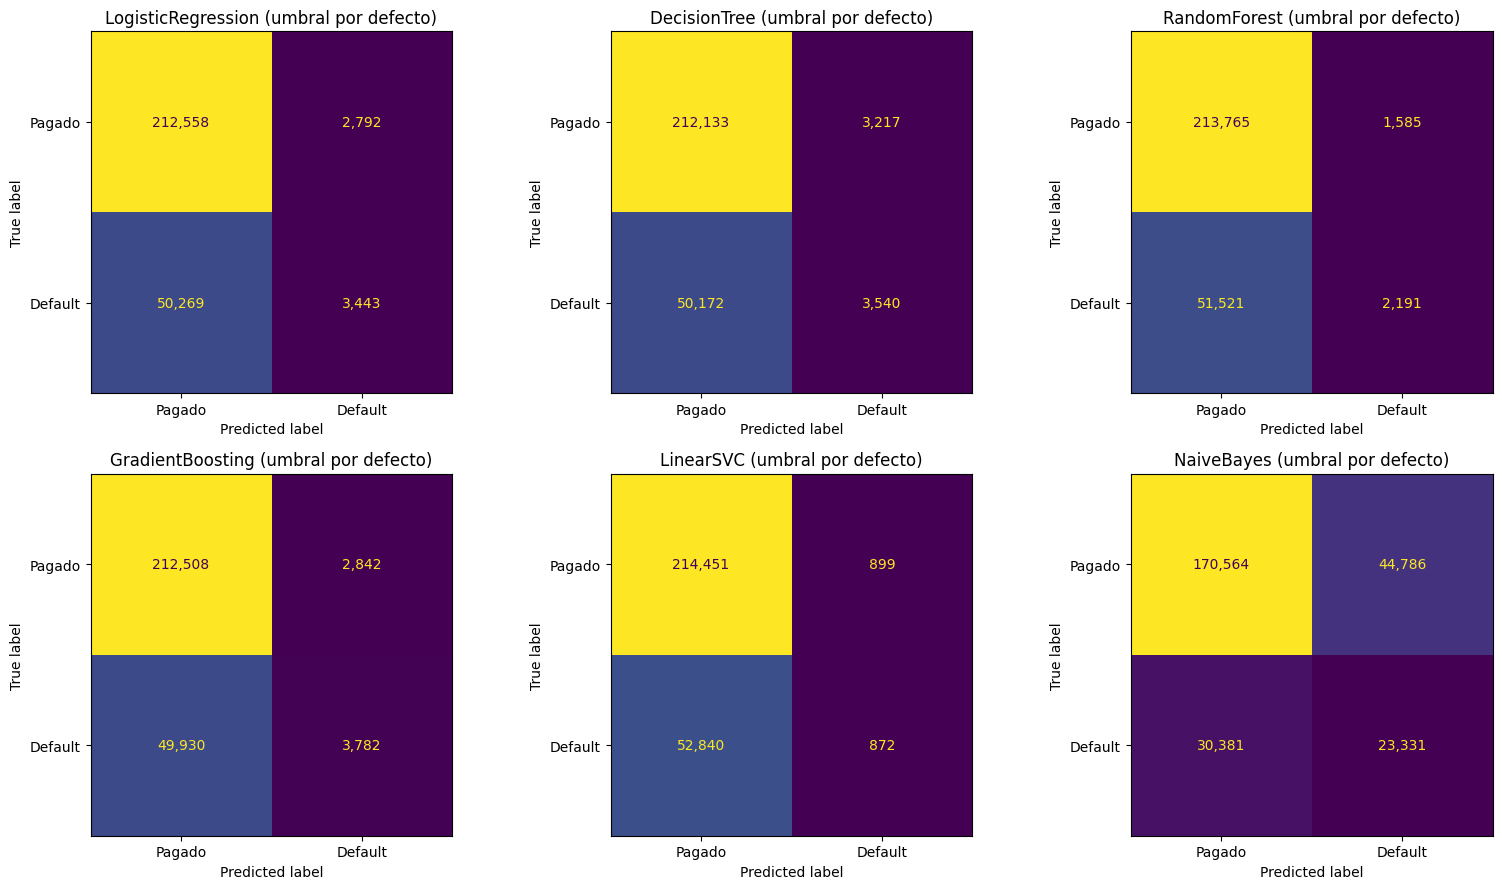

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))  # Una matriz de confusión por modelo
for ax, (nombre, r) in zip(axes.ravel(), resultados.items()):  # Recorre los modelos
    ConfusionMatrixDisplay(np.array(r["metricas"]["matriz_confusion"]), display_labels=["Pagado", "Default"]).plot(ax=ax, colorbar=False, values_format=",")  # Dibuja la matriz
    ax.set_title(f"{nombre} (umbral por defecto)")  # Título
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "03_matrices_confusion_sklearn")  # Exporta la figura
plt.show()  # Muestra la figura

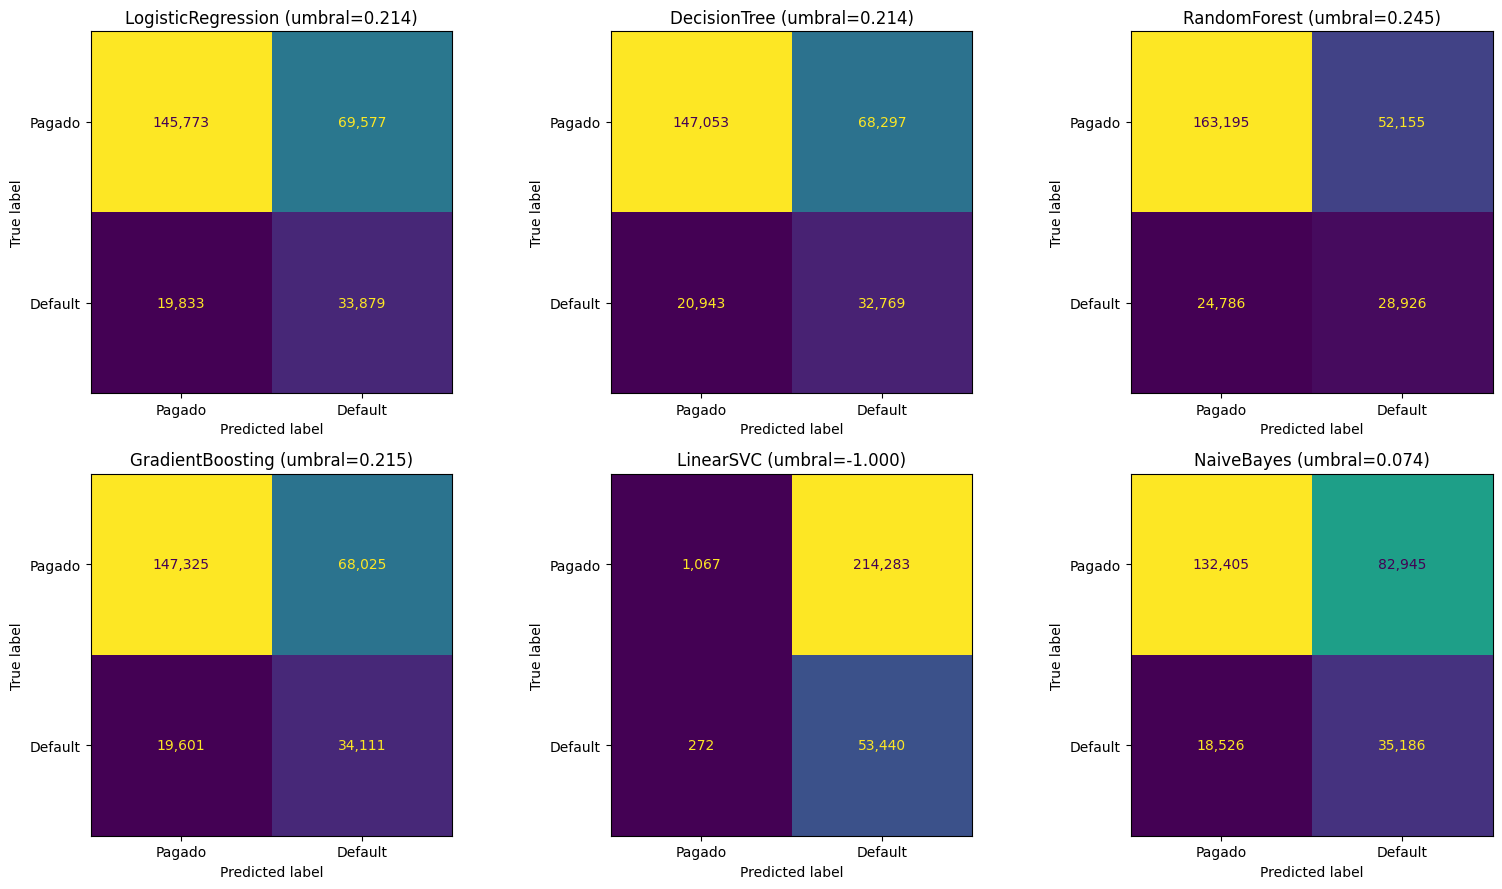

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))  # Matrices de confusión con el umbral elegido en train
for ax, (nombre, r) in zip(axes.ravel(), resultados.items()):  # Recorre los modelos
    ConfusionMatrixDisplay(np.array(r["metricas_umbral"]["matriz_confusion"]), display_labels=["Pagado", "Default"]).plot(ax=ax, colorbar=False, values_format=",")  # Dibuja la matriz
    ax.set_title(f"{nombre} (umbral={r['umbral']:.3f})")  # Título con el umbral
fig.tight_layout()  # Ajusta márgenes
plt.show()  # Muestra la figura

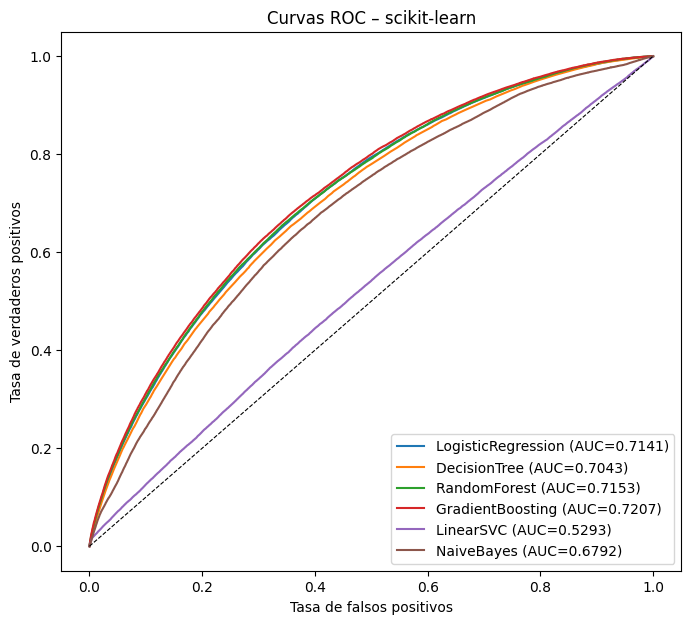

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))  # Curvas ROC de los seis modelos
for nombre in cfg.NOMBRES_MODELOS:  # Recorre los modelos en el orden canónico
    s = pd.read_parquet(cfg.DIR_SCORES_SK / f"{nombre}.parquet")  # Lee las puntuaciones guardadas
    fpr, tpr, _ = roc_curve(s[cfg.COL_TARGET], s["score"])  # Calcula la curva ROC
    ax.plot(fpr, tpr, label=f"{nombre} (AUC={resultados[nombre]['metricas']['roc_auc']:.4f})")  # Dibuja la curva
ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # Diagonal de referencia (azar)
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")  # Ejes
ax.set_title("Curvas ROC – scikit-learn"); ax.legend(loc="lower right")  # Título y leyenda
guardar_figura(fig, "03_roc_sklearn")  # Exporta la figura
plt.show()  # Muestra la figura

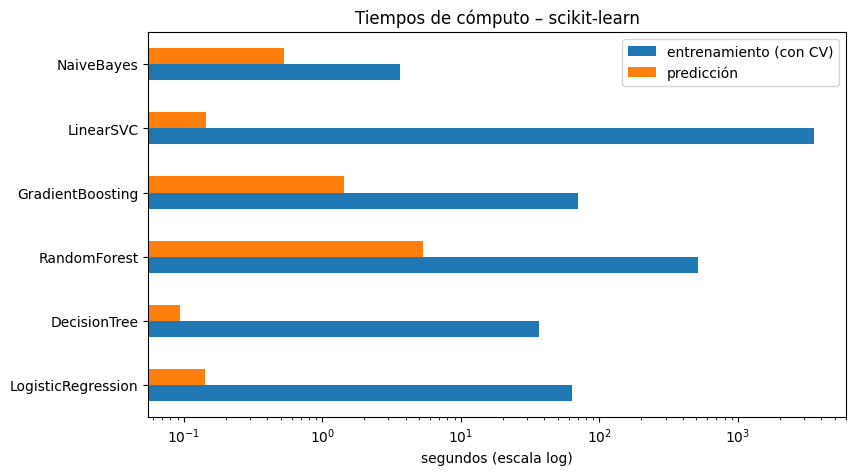

,entrenamiento (con CV),predicción
LogisticRegression,63.338732,0.141896
DecisionTree,36.685204,0.093865
RandomForest,518.896712,5.360159
GradientBoosting,70.615861,1.443551
LinearSVC,3549.439369,0.145680
NaiveBayes,3.636145,0.532384


In [12]:
tiempos = pd.DataFrame({n: {"entrenamiento (con CV)": r["tiempo_entrenamiento_s"], "predicción": r["tiempo_prediccion_s"]} for n, r in resultados.items()}).T  # Tiempos por modelo
ax = tiempos.plot.barh(figsize=(9, 5), logx=True)  # Barras en escala logarítmica
ax.set_xlabel("segundos (escala log)"); ax.set_title("Tiempos de cómputo – scikit-learn")  # Ejes y título
plt.show()  # Muestra la figura
tiempos  # Tabla de tiempos

## Interpretación de los resultados de scikit-learn

**Capacidad discriminante (AUC en test).** El mejor modelo es *gradient boosting*
(`HistGradientBoostingClassifier`, 100 iteraciones, profundidad 5): AUC = 0,7207. Le siguen el
bosque aleatorio (0,7153), la regresión logística (0,7141), el árbol de decisión (0,7043),
Naive Bayes (0,6792) y, muy por detrás, LinearSVC (0,5293). Los AUC de validación cruzada son
muy parecidos a los de test (p. ej., 0,7166 vs 0,7207 en boosting), así que no hay señales de
sobreajuste en la selección de hiperparámetros.

**Hiperparámetros.** El bosque y el boosting eligen el extremo superior de la malla
(100 árboles, profundidad 15; 100 iteraciones, profundidad 5): con 1,07 M de filas, modelos más
complejos todavía mejoran, por lo que una malla más amplia podría ganar algo de AUC. El árbol
de decisión muestra el sobreajuste clásico: profundidad 10 (0,696 en CV) supera a 15 (0,663).
En la regresión logística la regularización casi no importa (0,7096–0,7120 en CV): con un
millón de filas y 77 variables el término de penalización es despreciable.

**Métricas con el umbral por defecto (0,5).** La *accuracy* (≈ 0,80) apenas iguala a un modelo
trivial que siempre predice "pagado", y el *recall* es de solo 4–7 %: con un 20 % de defaults,
pocas probabilidades superan 0,5. Naive Bayes es la excepción (recall 0,43, accuracy 0,72)
porque sus probabilidades están mal calibradas (supone independencia y exagera la confianza).
Con el umbral que maximiza F1 **en train** (≈ 0,21), el F1 en test sube a 0,42–0,44 y el recall a
≈ 0,63 en todos los modelos útiles: el umbral importa tanto como el algoritmo.

**LinearSVC.** Su AUC (0,53 en test; 0,548 ± 0,033 en CV) es apenas mejor que el azar y muy
inestable entre pliegues. No es un problema de convergencia (en una prueba con 100 mil filas el
solucionador convergió en 371 iteraciones con el mismo AUC ≈ 0,48). La causa es la combinación de
la pérdida *hinge* con un 20 % de positivos muy solapados con los negativos: la solución óptima
está cerca de "clasificar todo como pagado" y el margen resultante casi no ordena el riesgo.
Además, `liblinear` penaliza también el intercepto (lo trata como una variable más), lo que
restringe precisamente el término que absorbe el desbalance. El umbral elegido en train (−1)
confirma la degeneración: para maximizar F1 hay que marcar casi todo como default (recall 0,99).
PySpark, que no penaliza el intercepto, obtiene 0,68 con el mismo modelo (notebook 04).

**Tiempos.** LinearSVC domina el costo (≈ 59 min, por el solucionador dual de un solo hilo
con C ≈ 0,93), seguido del bosque aleatorio (519 s). Los demás modelos, incluida la búsqueda de
*gradient boosting*, tardan menos de 75 s con los 12 hilos del equipo.